# Render Rollout Frames

Load rollouts from the multi_prior_rollout H5 file, select one, and render 5 evenly spaced frames.

In [2]:
%load_ext autoreload
%autoreload 2

import os

os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
os.environ["MUJOCO_GL"] = "egl"
os.environ["PYOPENGL_PLATFORM"] = "egl"

import h5py
import numpy as np
import mujoco
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scamper.environment.rodent import consts as rodent_consts

In [3]:
# Load the H5 file
h5_path = Path(
    "/home/mila/a/aidan.sirbu/SCAMPER/scratch/multi_prior_rollouts/goldenrodent_jax/rollout_data.h5"
)
h5f = h5py.File(h5_path, "r")

In [4]:
# List all available rollouts
rollout_index = []
for var_name in sorted(h5f.keys()):
    if var_name == "metadata":
        continue
    var_group = h5f[var_name]
    for pose_name in sorted(var_group.keys()):
        n_rollouts = var_group[pose_name]["qpos"].shape[0]
        n_steps = var_group[pose_name]["qpos"].shape[1]
        for i in range(n_rollouts):
            rollout_index.append(
                {
                    "idx": len(rollout_index),
                    "variance": var_name,
                    "pose": pose_name,
                    "rollout": i,
                    "steps": n_steps,
                }
            )

print(f"Total rollouts available: {len(rollout_index)}")
print("\nVariance groups and poses:")
for var_name in sorted(h5f.keys()):
    if var_name == "metadata":
        continue
    poses = sorted(h5f[var_name].keys())
    n = h5f[var_name][poses[0]]["qpos"].shape[0]
    print(f"  {var_name}: {len(poses)} poses, {n} rollouts each")

Total rollouts available: 14721

Variance groups and poses:
  deterministic: 21 poses, 1 rollouts each
  logvar_-0.5: 21 poses, 100 rollouts each
  logvar_-1.0: 21 poses, 100 rollouts each
  logvar_-2.0: 21 poses, 100 rollouts each
  logvar_-3.0: 21 poses, 100 rollouts each
  logvar_-4.0: 21 poses, 100 rollouts each
  logvar_0.0: 21 poses, 100 rollouts each
  predicted_logvar: 21 poses, 100 rollouts each


In [178]:
# Select a rollout
variance = "logvar_-2.0"  # e.g. "deterministic", "logvar_-2.0", "predicted_logvar"
pose = "neutral"  # e.g. "neutral", "clip1_frame0", "clip3_frame0"
rollout_idx = 2  # which rollout within this variance/pose

qpos = h5f[variance][pose]["qpos"][rollout_idx]  # (max_steps, 74)
print(f"Selected: {variance} / {pose} / rollout {rollout_idx}")
print(f"qpos shape: {qpos.shape}")

Selected: logvar_-2.0 / neutral / rollout 2
qpos shape: (1000, 74)


In [179]:
# XML paths (override these to use different models)
walker_xml = str(rodent_consts.RODENT_NO_TAIL_COLLISION_XML)
arena_xml = str(rodent_consts.ARENA_XML_PATH)

# Build combined arena+rodent model (matches the 74 DOF qpos from rollouts)
arena_spec = mujoco.MjSpec.from_file(arena_xml)
rodent_spec = mujoco.MjSpec.from_file(walker_xml)

frame = arena_spec.worldbody.add_frame(pos=(0, 0, 0), quat=(1, 0, 0, 0))
spawn_body = frame.attach_body(rodent_spec.body("walker"), "", suffix="-rodent")
spawn_body.add_freejoint(name="root")

model = arena_spec.compile()
data = mujoco.MjData(model)

print(f"Walker XML: {walker_xml}")
print(f"Arena XML:  {arena_xml}")
print(f"Model qpos dim: {model.nq} (H5 qpos dim: {qpos.shape[1]})")

render_height = 480
render_width = 640
camera = "close_profile-rodent"  # suffix appended during attach

renderer = mujoco.Renderer(model, height=render_height, width=render_width)
cam_id = mujoco.mj_name2id(model, mujoco.mjtObj.mjOBJ_CAMERA, camera)
print(f"Using camera: {camera} (id={cam_id})")

Walker XML: /home/mila/a/aidan.sirbu/SCAMPER/scamper/environment/rodent/xmls/rodent_no_tail_collisions.xml
Arena XML:  /home/mila/a/aidan.sirbu/SCAMPER/scamper/environment/rodent/xmls/arena.xml
Model qpos dim: 74 (H5 qpos dim: 74)
Using camera: close_profile-rodent (id=0)


In [180]:
# Render evenly spaced frames over a configurable time range
num_frames = 4
t_start = 0  # first timestep to render
t_end = 999  # last timestep to render

frame_indices = np.linspace(t_start, t_end, num_frames, dtype=int)

frames = []
for t in frame_indices:
    data.qpos[:] = np.array(qpos[t])
    mujoco.mj_forward(model, data)
    renderer.update_scene(data, camera=cam_id)
    frame = renderer.render()
    frames.append(frame.copy())

print(f"Rendered {num_frames} frames at timesteps: {frame_indices.tolist()}")

Rendered 4 frames at timesteps: [0, 333, 666, 999]


In [181]:
# Render video of the rollout with frame labels
import mediapy as media
from PIL import Image, ImageDraw, ImageFont

video_t_start = 0
video_t_end = qpos.shape[0]
video_fps = 50  # matches 50Hz simulation

# Load a bold font (fall back to default if unavailable)
try:
    font = ImageFont.truetype(
        "/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf", 24
    )
except OSError:
    font = ImageFont.load_default(size=24)

video_indices = np.arange(video_t_start, video_t_end)
video_frames = []
for t in video_indices:
    data.qpos[:] = np.array(qpos[t])
    mujoco.mj_forward(model, data)
    renderer.update_scene(data, camera=cam_id)
    frame = renderer.render().copy()

    # Burn in frame number
    img = Image.fromarray(frame)
    draw = ImageDraw.Draw(img)
    draw.text((10, 10), str(t), fill=(255, 255, 255), font=font)
    video_frames.append(np.array(img))

media.show_video(video_frames, fps=video_fps)

This browser does not support the video tag.


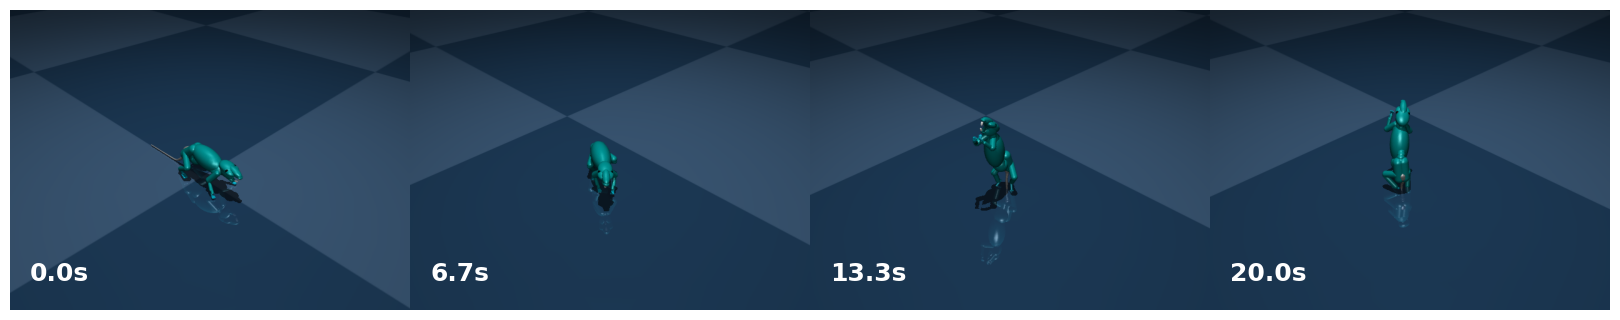

In [182]:
# Set the RGB color for the frame border (0-255 scale)
accent_rgb = (0, 170, 188)
accent_color = tuple(c / 255 for c in accent_rgb)

# Set the RGB color for the time labels (0-255 scale)
label_rgb = (255, 255, 255)
label_color = tuple(c / 255 for c in label_rgb)

# Save path and filename
save_dir = Path("/home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/random_generation")
save_name = f"rollout_frames_{variance}_{pose}_{rollout_idx}"

fig, axes = plt.subplots(1, num_frames, figsize=(num_frames * 4, 4))
plt.subplots_adjust(wspace=0, hspace=0)

for ax, frame, t in zip(axes, frames, frame_indices):
    ax.imshow(frame)
    ax.text(
        0.05,
        0.08,
        f"{t / 50:.1f}s",
        transform=ax.transAxes,
        fontsize=18,
        fontweight="bold",
        color=label_color,
        va="bottom",
        ha="left",
    )
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)

plt.tight_layout(pad=0)

# # Save as PDF and SVG
# save_dir.mkdir(parents=True, exist_ok=True)
# fig.savefig(save_dir / f"{save_name}.pdf", bbox_inches="tight", pad_inches=0)
# fig.savefig(save_dir / f"{save_name}.svg", bbox_inches="tight", pad_inches=0)
# fig.savefig(save_dir / f"{save_name}.png", bbox_inches="tight", pad_inches=0)
# print(f"Saved to {save_dir / save_name}.pdf and .svg and .png")

plt.show()

In [192]:
# Interactive motion trail viewer
# Build multi-rodent scene, then explore with camera sliders (EGL offscreen)
import ipywidgets as widgets
from IPython.display import display as ipy_display
import io, PIL.Image

# --- Trail configuration ---
trail_num_frames = 10  # number of rodent copies to place (ignored if override is set)
trail_t_start = 0  # first timestep
trail_t_end = 999  # last timestep
trail_timesteps_override = [
    0,
    111,
    150,
    222,
    400,
    600,
    700,
]  # explicit timesteps, e.g. [0, 100, 250, 500]; empty = use linspace

# Trajectory trace line (capsule segments along torso center)
trail_line_step = 5  # connect positions every N timesteps
trail_line_radius = 0.003  # line thickness
trail_line_rgb = (189, 19, 0)  # line color (0-255 scale)
trail_line_alpha = 0.8  # line opacity (0-1)

# Initial camera (world coordinates)
trail_cam_pos = [-0.7, 0.1, 0.25]  # camera position [x, y, z]
trail_cam_lookat = [0.0, 0.425, 0.0]  # point the camera looks at [x, y, z]
trail_cam_fovy = 45  # vertical field of view (degrees)

# Render resolution (used by the high-res render cell below)
trail_render_height = 1080
trail_render_width = 2048

# --- Build multi-rodent model ---
if trail_timesteps_override:
    trail_indices = np.array(trail_timesteps_override, dtype=int)
    trail_num_frames = len(trail_indices)
else:
    trail_indices = np.linspace(trail_t_start, trail_t_end, trail_num_frames, dtype=int)
trail_line_rgba = [c / 255 for c in trail_line_rgb] + [trail_line_alpha]

# Compute torso xpos at each trace timestep using the single-rodent model
torso_body_id = mujoco.mj_name2id(model, mujoco.mjtObj.mjOBJ_BODY, "torso-rodent")
line_t_start = trail_indices[0]
line_t_end = trail_indices[-1]
line_timesteps = np.arange(line_t_start, line_t_end + 1, trail_line_step)
torso_positions = []
for t in line_timesteps:
    data.qpos[:] = np.array(qpos[t])
    mujoco.mj_forward(model, data)
    torso_positions.append(data.xpos[torso_body_id].copy())

# Build model with multiple rodent copies
trail_spec = mujoco.MjSpec.from_file(arena_xml)
for i in range(trail_num_frames):
    rodent_spec_i = mujoco.MjSpec.from_file(walker_xml)
    frame_i = trail_spec.worldbody.add_frame(pos=(0, 0, 0), quat=(1, 0, 0, 0))
    body_i = frame_i.attach_body(rodent_spec_i.body("walker"), "", suffix=f"-t{i}")
    body_i.add_freejoint(name=f"root-t{i}")

# Add trajectory trace as capsule line segments between consecutive torso positions
for j in range(len(torso_positions) - 1):
    p1 = torso_positions[j].tolist()
    p2 = torso_positions[j + 1].tolist()
    trail_spec.worldbody.add_geom(
        name=f"line_seg_{j}",
        type=mujoco.mjtGeom.mjGEOM_CAPSULE,
        fromto=[*p1, *p2],
        size=[trail_line_radius, 0, 0],
        rgba=trail_line_rgba,
        contype=0,
        conaffinity=0,
    )

# Add a camera to the spec (needed for the high-res render cell)
cam_pos = np.array(trail_cam_pos, dtype=float)
cam_lookat = np.array(trail_cam_lookat, dtype=float)
look_dir = cam_lookat - cam_pos
cam_z = -look_dir / np.linalg.norm(look_dir)
world_up = np.array([0.0, 0.0, 1.0])
cam_x = np.cross(world_up, cam_z)
cam_x /= np.linalg.norm(cam_x)
cam_y = np.cross(cam_z, cam_x)
R = np.column_stack([cam_x, cam_y, cam_z])
trace = R[0, 0] + R[1, 1] + R[2, 2]
s = 2.0 * np.sqrt(1.0 + trace)
cam_quat = [
    0.25 * s,
    (R[2, 1] - R[1, 2]) / s,
    (R[0, 2] - R[2, 0]) / s,
    (R[1, 0] - R[0, 1]) / s,
]

overview_cam = trail_spec.worldbody.add_camera(name="trail_overview")
overview_cam.pos = cam_pos.tolist()
overview_cam.quat = cam_quat
overview_cam.fovy = trail_cam_fovy

# Add overhead light to the spec
overhead = trail_spec.worldbody.add_light(name="overhead")
overhead.pos = [0.0, 0.425, 3.0]
overhead.dir = [0, 0, -1]
overhead.diffuse = [1.0, 1.0, 1.0]
overhead.specular = [0.3, 0.3, 0.3]

trail_model = trail_spec.compile()

# Disable ALL tracking lights (each rodent copy brings one)
for i in range(trail_model.nlight):
    name = mujoco.mj_id2name(trail_model, mujoco.mjtObj.mjOBJ_LIGHT, i)
    if name and "tracking_light" in name:
        trail_model.light_diffuse[i] = [0, 0, 0]
        trail_model.light_specular[i] = [0, 0, 0]

trail_cam_id = mujoco.mj_name2id(
    trail_model, mujoco.mjtObj.mjOBJ_CAMERA, "trail_overview"
)

trail_data = mujoco.MjData(trail_model)

# Set each copy's qpos to a different timestep
nq_single = model.nq  # 74 DOF per rodent
for i, t in enumerate(trail_indices):
    start = i * nq_single
    trail_data.qpos[start : start + nq_single] = np.array(qpos[t])

mujoco.mj_forward(trail_model, trail_data)

print(
    f"Built trail with {trail_num_frames} poses at timesteps: {trail_indices.tolist()}"
)
print(f"Added {len(torso_positions) - 1} line segments (every {trail_line_step} steps)")

# --- Interactive viewer ---
interactive_height = 720
interactive_width = 1280

interactive_renderer = mujoco.Renderer(
    trail_model, height=interactive_height, width=interactive_width
)
free_cam = mujoco.MjvCamera()
free_cam.type = mujoco.mjtCamera.mjCAMERA_FREE

# Initialize from previous capture if available, otherwise from trail defaults
try:
    _has_capture = bool(captured_cam)
except NameError:
    captured_cam = {}
    _has_capture = False

if _has_capture:
    free_cam.azimuth = captured_cam["azimuth"]
    free_cam.elevation = captured_cam["elevation"]
    free_cam.distance = captured_cam["distance"]
    free_cam.lookat[:] = captured_cam["lookat"]
    print(
        f"Restored from capture: az={free_cam.azimuth:.1f} el={free_cam.elevation:.1f} "
        f"dist={free_cam.distance:.2f} lookat={captured_cam['lookat']}"
    )
else:
    free_cam.lookat[:] = trail_cam_lookat
    free_cam.distance = float(
        np.linalg.norm(np.array(trail_cam_pos) - np.array(trail_cam_lookat))
    )
    _offset = np.array(trail_cam_pos) - np.array(trail_cam_lookat)
    free_cam.azimuth = float(np.degrees(np.arctan2(_offset[1], _offset[0])))
    free_cam.elevation = float(
        np.degrees(np.arcsin(_offset[2] / np.linalg.norm(_offset)))
    )
    print("Initialized from trail_cam defaults")

img_widget = widgets.Image(
    format="jpeg", layout=widgets.Layout(width=f"{interactive_width}px")
)


def render_view(change=None):
    interactive_renderer.update_scene(trail_data, camera=free_cam)
    frame = interactive_renderer.render()
    buf = io.BytesIO()
    PIL.Image.fromarray(frame).save(buf, format="JPEG", quality=90)
    img_widget.value = buf.getvalue()


azimuth_slider = widgets.FloatSlider(
    value=free_cam.azimuth,
    min=-180,
    max=180,
    step=1,
    description="Azimuth",
    continuous_update=True,
    layout=widgets.Layout(width="500px"),
)
elevation_slider = widgets.FloatSlider(
    value=free_cam.elevation,
    min=-90,
    max=90,
    step=1,
    description="Elevation",
    continuous_update=True,
    layout=widgets.Layout(width="500px"),
)
distance_slider = widgets.FloatSlider(
    value=free_cam.distance,
    min=0.1,
    max=5.0,
    step=0.05,
    description="Distance",
    continuous_update=True,
    layout=widgets.Layout(width="500px"),
)
lookat_x = widgets.FloatSlider(
    value=free_cam.lookat[0],
    min=-3,
    max=3,
    step=0.05,
    description="Lookat X",
    continuous_update=True,
    layout=widgets.Layout(width="500px"),
)
lookat_y = widgets.FloatSlider(
    value=free_cam.lookat[1],
    min=-3,
    max=3,
    step=0.05,
    description="Lookat Y",
    continuous_update=True,
    layout=widgets.Layout(width="500px"),
)
lookat_z = widgets.FloatSlider(
    value=free_cam.lookat[2],
    min=-1,
    max=2,
    step=0.05,
    description="Lookat Z",
    continuous_update=True,
    layout=widgets.Layout(width="500px"),
)


def on_slider_change(change):
    free_cam.azimuth = azimuth_slider.value
    free_cam.elevation = elevation_slider.value
    free_cam.distance = distance_slider.value
    free_cam.lookat[:] = [lookat_x.value, lookat_y.value, lookat_z.value]
    render_view()


for s in [
    azimuth_slider,
    elevation_slider,
    distance_slider,
    lookat_x,
    lookat_y,
    lookat_z,
]:
    s.observe(on_slider_change, names="value")

# Capture button — saves current slider values so the next cell can read them
capture_label = widgets.Label(value="")
capture_btn = widgets.Button(description="Capture Camera", button_style="success")


def on_capture(btn):
    captured_cam["azimuth"] = azimuth_slider.value
    captured_cam["elevation"] = elevation_slider.value
    captured_cam["distance"] = distance_slider.value
    captured_cam["lookat"] = [lookat_x.value, lookat_y.value, lookat_z.value]
    capture_label.value = (
        f"Captured: az={captured_cam['azimuth']:.1f} "
        f"el={captured_cam['elevation']:.1f} "
        f"dist={captured_cam['distance']:.2f} "
        f"lookat={[f'{v:.2f}' for v in captured_cam['lookat']]}"
    )


capture_btn.on_click(on_capture)

render_view()

controls = widgets.VBox(
    [
        widgets.HBox([azimuth_slider, elevation_slider]),
        widgets.HBox([distance_slider]),
        widgets.HBox([lookat_x, lookat_y, lookat_z]),
        widgets.HBox([capture_btn, capture_label]),
    ]
)
ipy_display(widgets.VBox([img_widget, controls]))

Built trail with 7 poses at timesteps: [0, 111, 150, 222, 400, 600, 700]
Added 140 line segments (every 5 steps)
Restored from capture: az=-134.0 el=-15.0 dist=0.60 lookat=[0.25, -0.04999999999999982, 0.10000000000000009]


Azimuth: -134.0  Elevation: -15.0  Distance: 0.60  Lookat: [0.25, -0.04999999999999982, 0.10000000000000009]
Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/random_generation/rollout_trail_logvar_-2.0_neutral_2_custom.[pdf|svg|png]


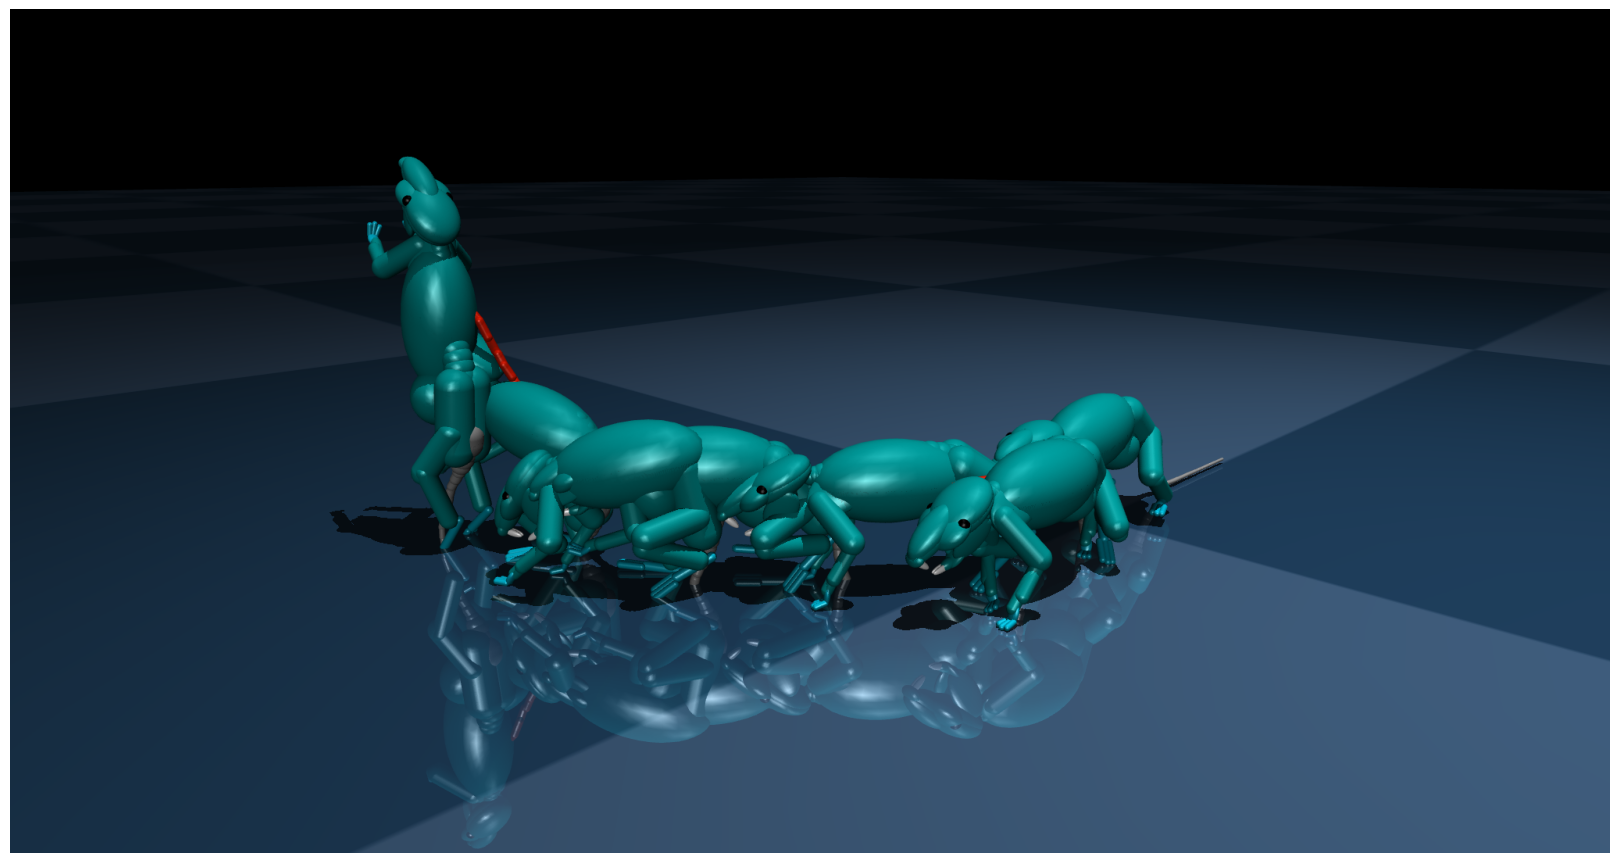

In [193]:
# Render high-res static frame using the camera captured by the button above
# Click "Capture Camera" in the widget above first, then run this cell

assert (
    captured_cam
), "Click 'Capture Camera' in the widget above before running this cell"

print(
    f"Azimuth: {captured_cam['azimuth']:.1f}  Elevation: {captured_cam['elevation']:.1f}  "
    f"Distance: {captured_cam['distance']:.2f}  Lookat: {captured_cam['lookat']}"
)

# Use MjvCamera directly (same as interactive viewer) at full resolution
hires_cam = mujoco.MjvCamera()
hires_cam.type = mujoco.mjtCamera.mjCAMERA_FREE
hires_cam.azimuth = captured_cam["azimuth"]
hires_cam.elevation = captured_cam["elevation"]
hires_cam.distance = captured_cam["distance"]
hires_cam.lookat[:] = captured_cam["lookat"]

hires_renderer = mujoco.Renderer(
    trail_model, height=trail_render_height, width=trail_render_width
)
hires_renderer.update_scene(trail_data, camera=hires_cam)
hires_frame = hires_renderer.render().copy()
hires_renderer.close()

# Display and save
trail_save_name_custom = f"rollout_trail_{variance}_{pose}_{rollout_idx}_custom"
fig, ax = plt.subplots(figsize=(16, 9))
ax.imshow(hires_frame)
ax.axis("off")
fig.subplots_adjust(left=0, right=1, top=1, bottom=0)

save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(
    save_dir / f"{trail_save_name_custom}.pdf", bbox_inches="tight", pad_inches=0
)
fig.savefig(
    save_dir / f"{trail_save_name_custom}.svg", bbox_inches="tight", pad_inches=0
)
fig.savefig(
    save_dir / f"{trail_save_name_custom}.png", bbox_inches="tight", pad_inches=0
)
print(f"Saved to {save_dir / trail_save_name_custom}.[pdf|svg|png]")
plt.show()